# Analysis

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Datasets

In [2]:
# load in turbine and met masts datasets
scada = pd.read_parquet('../../data/cleaned/scada_data.parquet')
scada_noloss = pd.read_parquet('../../data/cleaned/scada_noloss.parquet')
metmasts = pd.read_parquet('../../data/cleaned/metmasts_data.parquet')
reference = pd.read_parquet('../../data/cleaned/reference_power_curve.parquet')
wake = pd.read_parquet('../../data/cleaned/ALTA10_SCADA_with_wake_categories.parquet')

In [98]:
cutoff = pd.Timestamp('2026-01-14 05:40:00+00:00')   # replace with the first good timestamp

metmasts_clean = metmasts[pd.to_datetime(metmasts['utc'], utc = True) >= cutoff]

## Functions

In [138]:
def add_mm_wind_speed(data, metmast, wp_column = 'mm_wind_speed_hh', new_col = 'mm_wind_speed'):
    mm = (metmast[['utc', wp_column]]
          .assign(utc = lambda d: pd.to_datetime(d['utc'], utc = True))
          .rename(columns = {wp_column: new_col}))

    out = (data.assign(utc = lambda d: pd.to_datetime(d['utc'], utc = True))
               .merge(mm, on = 'utc', how = 'left', validate = 'many_to_one'))
    return out

In [141]:
def power_ratios(scada, ref, power_col = 'KPI_real_power_ac', mm_col = 'mm_wind_speed'):
    def snap(values, levels):
        arr = np.asarray(values, dtype = float)
        idx = np.clip(np.searchsorted(levels, arr), 1, len(levels) - 1)
        left, right = levels[idx - 1], levels[idx]
        nearest = np.where(arr - left <= right - arr, left, right)
        return np.where(np.isnan(arr), np.nan, nearest)

    # drops any existing power_ref so the lookup doesn't clash with it
    df = scada.drop(columns = 'power_ref', errors = 'ignore').copy()

    ad_levels = np.sort(ref['air_density_ref'].dropna().unique())
    ws_levels = np.sort(ref['wind_speed_ref'].dropna().unique())
    df['air_density_ref'] = snap(df['air_density'], ad_levels)

    lookup = ref[['wind_speed_ref', 'air_density_ref', 'power_ref']]

    # reference power at the turbine's wind speed and at the met mast's wind speed
    for ws_col, out_col in [('wind_speed', 'power_ref'), (mm_col, 'power_ref_mm')]:
        if ws_col not in df.columns:
            continue
        key = f'{ws_col}_ref'
        df[key] = snap(df[ws_col], ws_levels)
        df = df.merge(lookup.rename(columns = {'wind_speed_ref': key, 'power_ref': out_col}),
                      on = [key, 'air_density_ref'], how = 'left', validate = 'many_to_one')

    out = df.sort_values('utc', ignore_index = True)

    out['power_ratio_general'] = out[power_col] / out['power_ref'].replace(0, np.nan)
    out['power_ratio_theoretical'] = out[power_col] / out['KPI_theoretical_power'].replace(0, np.nan)
    if 'power_ref_mm' in out.columns:
        out['power_ratio_mm'] = out[power_col] / out['power_ref_mm'].replace(0, np.nan)

    return out

In [183]:
def add_implied_ws(data, ref, power_col = 'KPI_real_power_ac', max_frac = 0.9):
    out = data.copy()
    out['ws_implied'] = np.nan
    for ad, curve in ref.groupby('air_density_ref'):
        c = (curve.sort_values('wind_speed_ref')
                  .loc[lambda x: (x['power_ref'] > 0) & (x['power_ref'] <= max_frac * x['power_ref'].max())]
                  .drop_duplicates('power_ref'))
        c = c[c['power_ref'] == c['power_ref'].cummax()]          # rising part of the curve only
        if len(c) < 2:
            continue
        mask = (out['air_density_ref'] == ad) & out[power_col].between(c['power_ref'].min(), c['power_ref'].max())
        out.loc[mask, 'ws_implied'] = np.interp(out.loc[mask, power_col], c['power_ref'], c['wind_speed_ref'])
    return out

In [144]:
def add_metmast(data, metmast, wp_column = 'mm_wind_speed_hh', low = False, ws_low = 3, ws_up = 26):
    if low:
        cols1 = ['turbine', 'utc', 'wind_speed', 'KPI_real_power_ac', 'power_ref_mm']
    else:
        cols1 = ['turbine', 'utc', 'wind_speed', 'KPI_theoretical_power', 'KPI_real_power_ac', 'power_ref', 'power_ref_mm']

    cols2 = ['turbine', 'utc', 'wind_speed']
    
    a = data[cols1].assign(utc = lambda d: pd.to_datetime(d['utc'], utc = True))
    a = a[a['wind_speed'].between(ws_low, ws_up)]
    b = (metmast.assign(wind_speed = metmast[wp_column], turbine = 'Tower',
                        utc = lambda d: pd.to_datetime(d['utc'], utc = True))
                [cols2])

    combined = pd.concat([a, b], ignore_index = True)

    group_ranges = {1: (150, 159), 2: (161, 169), 3: (170, 177),
                    4: (178, 181), 5: (182, 192), 6: (193, 197)}
    rows = [(f"WTG{n}", g) for g, (lo, hi) in group_ranges.items() for n in range(lo, hi + 1)]
    rows.append(('Tower', 1))
    grouping = pd.DataFrame(rows, columns = ['turbine', 'group'])

    combined_all = combined.merge(grouping, on = 'turbine', how = 'left').sort_values('utc', ignore_index = True)

    return combined_all

In [107]:
def group_metrics(data, group, reference, low = None, up = None):
    turbines = data.loc[(data['group'] == group) & (data['turbine'] != reference)
                        & (data['turbine'] != 'Tower'), 'turbine'].unique()

    results = []
    for turbine in sorted(turbines):
        p = pair_turbines(data, turbine, reference, low = low, up = up).dropna(
            subset = ['wind_speed_turbine', 'wind_speed_reference'])
        x, y = p['wind_speed_reference'], p['wind_speed_turbine']

        try:
            slope, intercept = np.polyfit(x, y, 1) if len(p) > 1 else (np.nan, np.nan)
        except (np.linalg.LinAlgError, ValueError):
            slope, intercept = np.nan, np.nan

        results.append({'turbine': turbine, 'reference': reference, 'n': len(p),
                        'bias': p['difference'].mean(), 'sd_diff': p['difference'].std(),
                        'corr': x.corr(y), 'slope': slope, 'intercept': intercept})

    out = pd.DataFrame(results, columns = ['turbine', 'reference', 'n', 'bias', 'sd_diff',
                                           'corr', 'slope', 'intercept'])
    return out.sort_values('corr', ascending = False, ignore_index = True)

In [149]:
def pair_turbines(data, turbine, reference, low = None, up = None):
    cols_t = ['turbine', 'utc', 'wind_speed', 'KPI_theoretical_power', 'KPI_real_power_ac', 'power_ref', 'power_ref_mm']
    cols_r = ['turbine', 'utc', 'wind_speed']

    a = data.loc[data['turbine'] == turbine, cols_t]
    b = data.loc[data['turbine'] == reference, cols_r]

    out = a.merge(b, on = 'utc', how = 'inner', suffixes = ('_1', '_2'))
    out = out.rename(columns = {'turbine_1': 'turbine', 'turbine_2': 'reference',
                                'wind_speed_1': 'wind_speed_turbine', 'wind_speed_2': 'wind_speed_reference',
                                'KPI_theoretical_power': 'theoretical_power_turbine',
                                'KPI_real_power_ac': 'real_power_turbine'})

    if low is not None:
        out = out[out['wind_speed_reference'] >= low]
    if up is not None:
        out = out[out['wind_speed_reference'] <= up]

    out['difference'] = out['wind_speed_turbine'] - out['wind_speed_reference']

    return out[['utc', 'turbine', 'reference', 'wind_speed_turbine', 'wind_speed_reference', 'difference',
                'theoretical_power_turbine', 'real_power_turbine', 'power_ref', 'power_ref_mm']]

In [150]:
def pair_turbines_month(data, turbine, reference, low = None, up = None):
    p = pair_turbines(data, turbine, reference, low = low, up = up)
    p['month'] = p['utc'].dt.tz_localize(None).dt.to_period('M')

    keys = ['month', 'turbine', 'reference']

    # wind speed difference averaged over every paired row
    ws = p.groupby(keys).agg(
        difference = ('difference', 'mean'),
        n_pairs = ('difference', 'count'),
    )

    # power sums only over rows where all three power values exist, so the sums are comparable
    pw = (p.dropna(subset = ['real_power_turbine', 'theoretical_power_turbine', 'power_ref'])
           .groupby(keys).agg(
               actual = ('real_power_turbine', 'sum'),
               theoretical = ('theoretical_power_turbine', 'sum'),
               reference_power = ('power_ref', 'sum'),
               reference_power_mm = ('power_ref_mm', 'sum'),
               n_obs = ('real_power_turbine', 'count'),
           ))

    monthly = ws.join(pw, how = 'left').reset_index()

    monthly['power_ratio_theoretical'] = np.where(
        (monthly['theoretical'] > 0) & (monthly['actual'] > 0),
        monthly['actual'] / monthly['theoretical'],
        np.nan,
    )

    monthly['power_ratio_reference'] = np.where(
        (monthly['reference_power'] > 0) & (monthly['actual'] > 0),
        monthly['actual'] / monthly['reference_power'],
        np.nan,
    )

    monthly['power_ratio_reference_mm'] = np.where(
        (monthly['reference_power_mm'] > 0) & (monthly['actual'] > 0),
        monthly['actual'] / monthly['reference_power_mm'],
        np.nan,
    )

    return monthly

In [155]:
def plot_pair_turbines_month(data, turbine, reference, ratio_col = 'power_ratio_reference', 
                             low = None, up = None, min_obs = 0, ma = '7D', ma_min_periods = 144):
    # monthly summary
    df = pair_turbines_month(data, turbine, reference, low = low, up = up).sort_values('month')
    df['start'] = df['month'].dt.start_time.dt.tz_localize('UTC')
    df['end'] = df['month'].dt.end_time.dt.tz_localize('UTC')
    df['mid'] = df['start'] + (df['end'] - df['start']) / 2
    df.loc[df['n_obs'].fillna(0) < min_obs, ratio_col] = np.nan

    # 10-min difference on a regular grid so gaps show as breaks
    p = pair_turbines(data, turbine, reference, low = low, up = up).dropna(
        subset = ['wind_speed_turbine', 'wind_speed_reference'])
    s = p.set_index('utc')['difference'].sort_index().asfreq('10min')
    rolling = s.rolling(ma, center = True, min_periods = ma_min_periods).mean() if ma is not None else None

    ratio_labels = {'power_ratio_theoretical': 'Real / Theoretical',
                    'power_ratio_reference': 'Real / Reference'}

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize = (12, 8), sharex = True)

    # Top: monthly power ratio
    ax1.plot(df['mid'], df[ratio_col], lw = 1, alpha = 0.7, marker = 'o')
    ax1.axhline(1, color = 'black', lw = 0.8)
    ax1.set_ylabel(f"Power Ratio\n({ratio_labels.get(ratio_col, ratio_col)})")
    lo, hi = df[ratio_col].min(), df[ratio_col].max()
    ax1.set_ylim(min(0.75, lo if pd.notna(lo) else 0.75) - 0.02, max(1.25, hi if pd.notna(hi) else 1.25) + 0.02)
    ax1.set_title(f'Monthly Power Ratio: {turbine}')
    ax1.grid(alpha = 0.3)

    # Top: monthly power ratio
    ax2.plot(df['mid'], df['power_ratio_reference_mm'], lw = 1, alpha = 0.7, marker = 'o')
    ax2.axhline(1, color = 'black', lw = 0.8)
    ax2.set_ylabel(f"Power Ratio\n(power_ratio_reference_mm)")
    lo, hi = df['power_ratio_reference_mm'].min(), df['power_ratio_reference_mm'].max()
    ax2.set_ylim(min(0.75, lo if pd.notna(lo) else 0.75) - 0.02, max(1.25, hi if pd.notna(hi) else 1.25) + 0.02)
    ax2.set_title(f'Monthly Power Ratio (Metmast Wind Measurment): {turbine}')
    ax2.grid(alpha = 0.3)

    # Bottom: 10-min difference, moving average, and monthly mean
    ax3.plot(s.index, s.values, lw = 0.5, alpha = 0.5, label = '10-min')
    if rolling is not None:
        ax3.plot(rolling.index, rolling.values, color = 'red', lw = 1.5, label = f'{ma} moving average')
    ax3.axhline(0, color = 'black', lw = 0.8, ls = ':')
    ax3.set_ylabel(f'Wind Speed Difference (m/s)\n{turbine} − {reference}')
    ax3.set_xlabel('Date (UTC)')
    ax3.set_title(f'Wind Speed Difference: {turbine} vs {reference}, n = {s.notna().sum()}')
    ax3.legend(loc = 'upper right')
    ax3.grid(alpha = 0.3)

    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

In [128]:
def plot_pair_diff_ts(data, turbine, reference, month = None, low = None, up = None,
                      ma = '7D', min_periods = 144):
    p = pair_turbines(data, turbine, reference, low = low, up = up).dropna(
        subset = ['wind_speed_turbine', 'wind_speed_reference'])

    # regular 10-min grid so gaps show as breaks instead of straight lines
    s = p.set_index('utc')['difference'].sort_index().asfreq('10min')

    # moving average on the full series, centered, so month edges aren't truncated
    rolling = s.rolling(ma, center = True, min_periods = min_periods).mean() if ma is not None else None

    if month is not None:
        m = pd.Period(month, freq = 'M')
        start = m.start_time.tz_localize('UTC')
        end = m.end_time.tz_localize('UTC')
        s = s.loc[start:end]
        if rolling is not None:
            rolling = rolling.loc[start:end]

    n = s.notna().sum()
    period = f', {month}' if month is not None else ''

    fig, ax = plt.subplots(figsize = (12, 5))
    ax.plot(s.index, s.values, lw = 0.5, alpha = 0.6, label = f'Difference {turbine} − {reference}')
    if rolling is not None:
        ax.plot(rolling.index, rolling.values, color = 'red', lw = 1.5, label = f'{ma} moving average (centered)')
    ax.axhline(0, color = 'k', lw = 0.8)
    ax.set(xlabel = 'Date/time (UTC)', ylabel = 'Wind speed difference (m/s)',
           title = f'{turbine} − {reference} Wind Speed Difference{period}, n = {n}')
    ax.legend()
    ax.grid(alpha = 0.3)
    fig.autofmt_xdate()
    plt.show()

## Generating Dataset

In [148]:
data = add_mm_wind_speed(scada_noloss, metmasts_clean)
data = power_ratios(data, reference, power_col = 'KPI_real_power_ac')
data = add_metmast(data, metmasts_clean, wp_column = 'mm_wind_speed_hh', low = False, ws_low = 3, ws_up = 26)

In [112]:
group_metrics(data, 1, 'Tower', low = None, up = None)

,turbine,reference,n,bias,sd_diff,corr,slope,intercept
0,WTG153,Tower,29886,0.152504,1.019519,0.983711,1.081889,-0.681843
1,WTG154,Tower,25892,-0.916617,1.127490,0.972786,1.049641,-1.464609
2,WTG155,Tower,28928,-0.527791,1.150226,0.972224,0.976858,-0.291175
3,WTG152,Tower,25283,0.752106,1.757001,0.967992,1.217722,-1.530864
4,WTG156,Tower,27576,-0.909657,1.233768,0.966431,1.003638,-0.948515
5,WTG150,Tower,27301,1.260456,1.844092,0.966425,1.224908,-1.041835
6,WTG151,Tower,25920,0.648091,1.717858,0.965150,1.191008,-1.396034
7,WTG157,Tower,27138,0.050741,1.471953,0.955965,0.975183,0.292951
8,WTG158,Tower,26985,-0.731903,1.830339,0.933339,1.047086,-1.235871
9,WTG159,Tower,23037,0.092013,2.209397,0.915232,1.093267,-0.843110


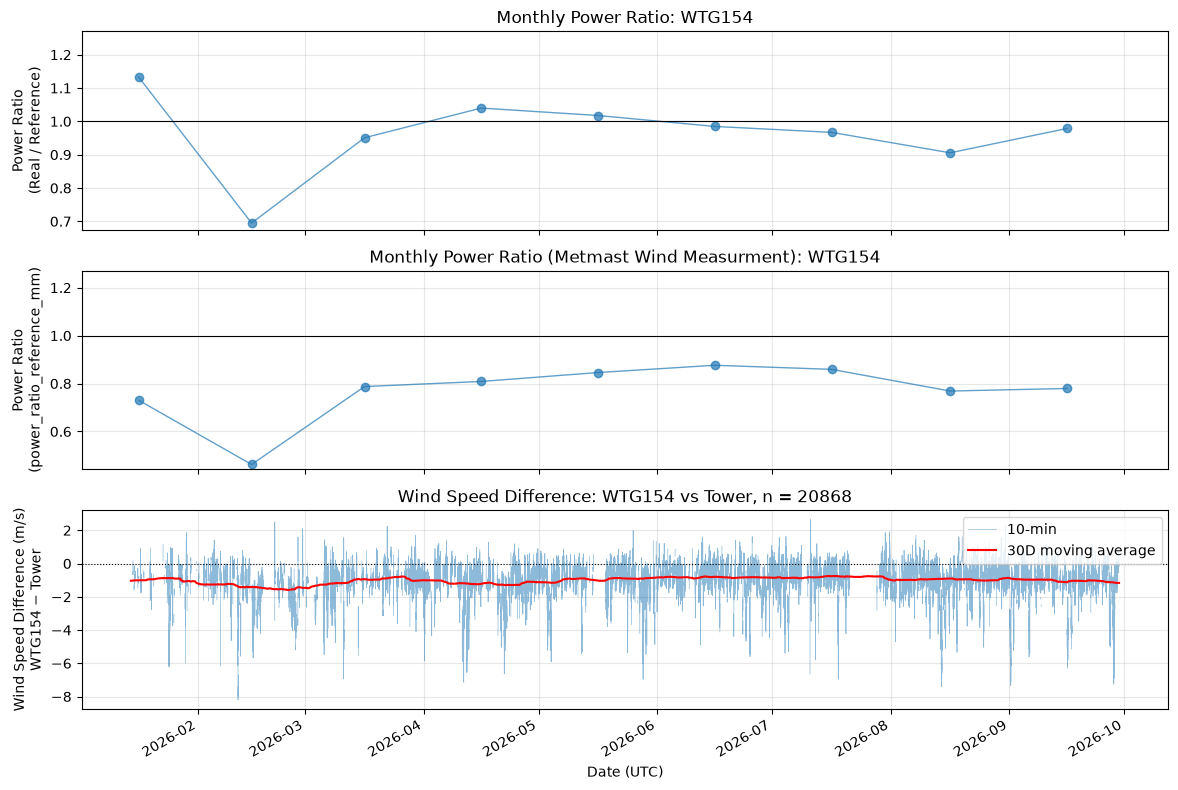

In [159]:
plot_pair_turbines_month(data, 'WTG154', 'Tower', ratio_col = 'power_ratio_reference', 
                             low = None, up = 15, min_obs = 0, ma = '30D', ma_min_periods = 144)

In [136]:
pair_turbines_month(data, 'WTG154', 'Tower', low = None, up = None)

,month,turbine,reference,difference,n_pairs,actual,theoretical,reference_power,n_obs,power_ratio_theoretical,power_ratio_reference
0,2026-01,WTG154,Tower,-1.001390,542,2.917082e+05,2.303163e+05,265673.0,529,1.266555,1.097997
1,2026-02,WTG154,Tower,-1.435137,1775,9.571505e+05,1.410536e+06,1527339.0,1775,0.678572,0.626679
2,2026-03,WTG154,Tower,-0.867625,2743,3.542488e+06,4.146356e+06,4439454.0,2743,0.854362,0.797956
3,2026-04,WTG154,Tower,-1.179958,3485,5.334307e+06,5.166028e+06,5574895.0,3485,1.032574,0.956844
4,2026-05,WTG154,Tower,-0.891992,3614,5.924384e+06,6.159580e+06,6523139.0,3615,0.961816,0.908211
5,2026-06,WTG154,Tower,-0.637192,3788,7.342447e+06,7.494475e+06,7907462.0,3789,0.979715,0.928547
6,2026-07,WTG154,Tower,-0.679041,2954,4.941554e+06,5.211360e+06,5581238.0,2954,0.948227,0.885387
7,2026-08,WTG154,Tower,-0.854799,3718,4.801831e+06,5.017264e+06,5364011.0,3552,0.957062,0.895194
8,2026-09,WTG154,Tower,-1.017266,3273,4.554288e+06,4.516885e+06,4770034.0,3261,1.008281,0.954770


## Second Attempt

In [170]:
a = power_ratios(add_mm_wind_speed(scada_noloss, metmasts_clean), reference)

d = a[a['mm_wind_speed'].between(4, 15)    
      & (a['KPI_real_power_ac'] > 0)             
      & a['wind_speed'].notna()].copy()
d['diff_mm'] = d['wind_speed'] - d['mm_wind_speed']

In [176]:
one = ['WTG150', 'WTG151', 'WTG152', 'WTG153', 'WTG154', 'WTG155', 'WTG156', 'WTG157', 'WTG158', 'WTG159']

d = d[d['turbine'].isin(one)]

In [177]:
d['bin'] = pd.cut(d['mm_wind_speed'], np.arange(4, 15, 1))
bias_bins = d.pivot_table(index = 'turbine', columns = 'bin', values = 'diff_mm',
                          aggfunc = 'median', observed = True)

In [178]:
bias_bins

bin,"(4, 5]","(5, 6]","(6, 7]","(7, 8]","(8, 9]","(9, 10]","(10, 11]","(11, 12]","(12, 13]","(13, 14]"
turbine,,,,,,,,,,
WTG150,-0.201117,-0.295575,-0.024553,0.277379,0.715270,1.272316,1.761321,2.204870,2.468663,2.690463
WTG151,-0.597351,-0.652516,-0.598821,-0.222754,0.292315,0.669136,1.058017,1.360151,1.636518,1.674078
WTG152,-0.580053,-0.563909,-0.365318,-0.085933,0.393422,0.834956,1.228994,1.444240,1.641899,1.840342
WTG153,-0.215150,-0.355379,-0.299629,-0.181495,-0.014088,0.121838,0.306689,0.428324,0.583938,0.691729
WTG154,-1.045885,-1.102968,-1.092272,-1.026959,-0.985818,-0.871125,-0.712335,-0.568624,-0.442044,-0.353873
WTG155,-0.048478,-0.368129,-0.496111,-0.592835,-0.651205,-0.679432,-0.574797,-0.482697,-0.451023,-0.402318
WTG156,-0.710954,-0.879060,-1.046371,-1.113554,-1.222553,-1.185149,-1.060709,-0.906700,-0.801660,-0.733220
WTG157,0.503866,0.220511,-0.072151,-0.268893,-0.253775,-0.197047,-0.015030,0.146664,0.215614,0.274505
WTG158,-0.671348,-0.954519,-1.095329,-1.250705,-1.226593,-1.090928,-0.966395,-0.750070,-0.671241,-0.662086


In [179]:
d = add_implied_ws(d, reference)
d['diff_power'] = d['wind_speed'] - d['ws_implied']

In [180]:
d

,utc,turbine,air_density,KPI_temp_ambient_merged,KPI_temp_ambient,KPI_theoretical_power,KPI_real_power_ac,real_power_ac,KPI_wind_speed,wind_speed,...,power_ref,mm_wind_speed_ref,power_ref_mm,power_ratio_general,power_ratio_theoretical,power_ratio_mm,diff_mm,bin,ws_implied,diff_power
82227,2026-01-14 11:20:00+00:00,WTG151,1.054770,18.606110,18.606110,0.000000,4.588731,58.903004,3.746850,3.738679,...,9.0,4.0,67.0,0.509859,NaN,0.068489,-0.468417,"(4, 5]",3.184909,0.553770
82228,2026-01-14 11:20:00+00:00,WTG152,1.050940,19.670744,19.670744,0.000000,28.088667,76.690608,3.760355,3.760808,...,67.0,4.0,67.0,0.419234,NaN,0.419234,-0.446289,"(4, 5]",3.664557,0.096250
82229,2026-01-14 11:20:00+00:00,WTG153,1.057919,17.736464,17.736464,112.519900,0.307897,17.586188,4.048819,4.059913,...,67.0,4.0,67.0,0.004595,0.002736,0.004595,-0.147184,"(4, 5]",NaN,NaN
82417,2026-01-14 12:00:00+00:00,WTG152,1.052012,19.328838,19.328838,0.000000,50.686905,81.801291,3.590320,3.560037,...,9.0,4.0,67.0,5.631878,NaN,0.756521,-0.574590,"(4, 5]",3.859370,-0.299333
82418,2026-01-14 12:00:00+00:00,WTG153,1.055677,18.312216,18.312216,4.194753,21.208113,33.282410,3.893132,3.892464,...,67.0,4.0,67.0,0.316539,5.055867,0.316539,-0.242163,"(4, 5]",3.605242,0.287222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1624393,2026-09-29 14:50:00+00:00,WTG154,1.049513,20.740255,20.740255,2694.272500,2828.918200,2829.521652,14.081191,14.080196,...,2840.0,14.0,2840.0,0.996098,1.049975,0.996098,0.275490,"(13, 14]",NaN,NaN
1624394,2026-09-29 14:50:00+00:00,WTG155,1.059581,17.944294,17.944294,2718.975600,2840.526400,2841.047931,14.424878,14.423005,...,2849.0,14.0,2844.0,0.997026,1.044705,0.998779,0.618299,"(13, 14]",NaN,NaN
1624395,2026-09-29 14:50:00+00:00,WTG156,1.063934,16.751902,16.751902,2746.269500,2851.022000,2850.015517,15.119856,15.106626,...,2850.0,14.0,2844.0,1.000359,1.038144,1.002469,1.301920,"(13, 14]",NaN,NaN
1624396,2026-09-29 14:50:00+00:00,WTG157,1.067190,15.866397,15.866397,2769.358600,2834.456300,2834.657215,16.267073,16.259286,...,2850.0,14.0,2844.0,0.994546,1.023506,0.996644,2.454580,"(13, 14]",NaN,NaN


In [181]:
s = d.groupby('turbine').agg(
    n = ('diff_mm', 'size'),
    bias_mm = ('diff_mm', 'median'),
    bias_power = ('diff_power', 'median'),
    ws_sum = ('wind_speed', 'sum'),
    mm_sum = ('mm_wind_speed', 'sum'),
    pref_sum = ('power_ref', 'sum'),
    pref_mm_sum = ('power_ref_mm', 'sum'),
)
s['ratio_mm'] = s['ws_sum'] / s['mm_sum']               
s['expected_energy_error'] = s['pref_sum'] / s['pref_mm_sum'] - 1   
s['bias_vs_site'] = s['bias_mm'] - s['bias_mm'].median()
s = s.drop(columns = ['ws_sum', 'mm_sum', 'pref_sum', 'pref_mm_sum']).sort_values('bias_vs_site')

In [182]:
s

,n,bias_mm,bias_power,ratio_mm,expected_energy_error,bias_vs_site
turbine,,,,,,
WTG156,20729,-0.952625,-0.033008,0.892116,-0.185449,-0.755465
WTG158,18919,-0.935250,0.102389,0.907208,-0.170403,-0.738090
WTG154,19569,-0.818468,-0.210137,0.894706,-0.165857,-0.621308
WTG159,15612,-0.494246,0.088125,0.956290,-0.091079,-0.297086
WTG155,18508,-0.477217,0.429061,0.939366,-0.110876,-0.280056
WTG157,15972,0.082896,1.554325,0.998397,-0.033282,0.280056
WTG153,20973,0.112486,0.215491,1.001296,-0.017862,0.309647
WTG151,18608,0.489213,-0.041355,1.043094,0.016245,0.686373
WTG152,18160,0.579813,0.092340,1.051446,0.027474,0.776973
